# Reliability Analysis for Preventive Maintenance

**Academic statistics project — EMINES, Mohammed VI Polytechnic University (2025–2026)**  
**Original group:** Saif Eddine Kaddouri, Marouane Zemrani, Yassine Hannane, and Youssef Laabadi.  
**Supervisor:** Abdelkrim Alahyane.

## Goal

We study how probabilistic lifetime models can help assess reliability and inform preventive maintenance. The motivating case is a hypothetical fleet of **1,000 servers**. The original group report and presentation were written in French; this **standalone English notebook** briefly explains the mathematics and implements the principal analyses.

**Data and reproducibility.** The original simulated dataset and random seed are unavailable. Accordingly, we generate a *new* reproducible sample of 1,000 independent Weibull lifetimes (shape $\beta=2$, scale $\eta=3$ thousand hours). Numerical estimates, test statistics, and plots can differ from the French report. They are **recomputed**, not copied or forced to match. The observations are simulated, not real industrial failure data.

**Original report → notebook:** probability foundations (Sections 2–3) → server lifetime analysis (Section 4) → statistical extensions, bootstrap and tests (Section 5). The notebook distinguishes theoretical formulas from simulated estimates and corrects statistical inconsistencies where necessary.

**How to use:** Run all cells in order. Requires Python 3.10+ with NumPy, SciPy, pandas, Matplotlib and Jupyter. All figures and tables are displayed *inside this notebook*; no companion data files are required. The bootstrap tests can take some time.

In [1]:
import sys
from math import factorial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy import stats, integrate

SEED = 2026
N = 1_000
B_BOOT = 600      # Nonparametric bootstrap replicates for parameter uncertainty
B_KS = 299        # Parametric bootstrap replicates for goodness-of-fit tests
                  # Raise to 4999+ for more precise Monte Carlo p-values

rng_data = np.random.default_rng(SEED)
rng_arch = np.random.default_rng(SEED + 1)
rng_boot = np.random.default_rng(SEED + 2)
rng_ks = np.random.default_rng(SEED + 3)

plt.rcParams.update({'figure.figsize': (8, 4.5), 'font.size': 10})

def show_plot():
    plt.tight_layout()
    plt.show()

print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__} | pandas {pd.__version__}')

Python 3.13.5 | NumPy 2.3.5 | SciPy 1.17.0 | pandas 2.2.3


## 0. Mathematical background from the French report

### Exponential distribution and the memoryless property

For an exponential lifetime $X\sim\operatorname{Exp}(\lambda)$, with rate $\lambda>0$:

$$f_X(t)=\lambda e^{-\lambda t},\quad R_X(t)=P(X>t)=e^{-\lambda t},\quad t\ge0.$$

Integration by parts yields $E[X^n]=n!/\lambda^n$; in particular, $E[X]=1/\lambda$ and $\operatorname{Var}(X)=1/\lambda^2$.

Its distinctive **memoryless property** is

$$P(X>s+t\mid X>s)=\frac{R_X(s+t)}{R_X(s)}=e^{-\lambda t}=P(X>t).$$

Under continuity and nondegeneracy assumptions, this property characterizes the exponential distribution. It entails a **constant** hazard, so it is inadequate when failure risk rises with equipment age.

### Reliability and the failure hazard

For a nonnegative continuous lifetime $T$ (density $f$, CDF $F$):

$$R(t)=P(T>t)=1-F(t),\qquad h(t)=\frac{f(t)}{R(t)}=-\frac{d}{dt}\log R(t),$$

$$R(t)=\exp\!\left(-\int_0^t h(u)\,du\right),\qquad E[T]=\int_0^\infty R(t)\,dt.$$

For a component still functioning at age $t_0$, its conditional survival probability after another $x$ time units is $R(t_0+x)/R(t_0)$. Its **mean residual life** is $\int_{t_0}^\infty R(u)du/R(t_0)$.

### Series and parallel systems

For two *independent*, nonrepairable components of lifetimes $T_1,T_2$:

- **Series:** failure occurs with the first failed component, $T_s=\min(T_1,T_2)$.
- **Parallel:** both must fail, $T_p=\max(T_1,T_2)$.

If $T_i\sim\operatorname{Exp}(\lambda_i)$ then

$$R_s(t)=e^{-(\lambda_1+\lambda_2)t},\quad R_p(t)=e^{-\lambda_1t}+e^{-\lambda_2t}-e^{-(\lambda_1+\lambda_2)t}.$$

### Weibull and Erlang distributions

A Weibull lifetime with shape $\beta$ and scale $\eta$ has

$$R(t)=e^{-(t/\eta)^\beta},\quad h(t)=\frac{\beta}{\eta}(t/\eta)^{\beta-1}.$$

For $\beta<1$, the hazard decreases; for $\beta=1$, it is constant (exponential); for $\beta>1$, it **increases** with age.

An Erlang lifetime is the sum of $k$ independent exponentials with equal rate $\lambda$, where $k$ is a positive integer. Its survival function is

$$R(t)=e^{-\lambda t}\sum_{j=0}^{k-1}\frac{(\lambda t)^j}{j!}.$$

These formulas motivate the simulation and model comparisons below.

In [2]:
# Numerical checks of the exponential distribution and its memorylessness.
rate = 0.5  # per 1,000 hours
exp_dist = stats.expon(scale=1 / rate)
assert all(np.isclose(exp_dist.moment(n), factorial(n) / rate**n) for n in range(1, 5))
s, x = 1.2, 0.8
conditional_survival = exp_dist.sf(s + x) / exp_dist.sf(s)
assert np.isclose(conditional_survival, exp_dist.sf(x))
print(f'P(X > {s+x:g} | X > {s:g}) = {conditional_survival:.4f}; '
      f'P(X > {x:g}) = {exp_dist.sf(x):.4f}')

P(X > 2 | X > 1.2) = 0.6703; P(X > 0.8) = 0.6703


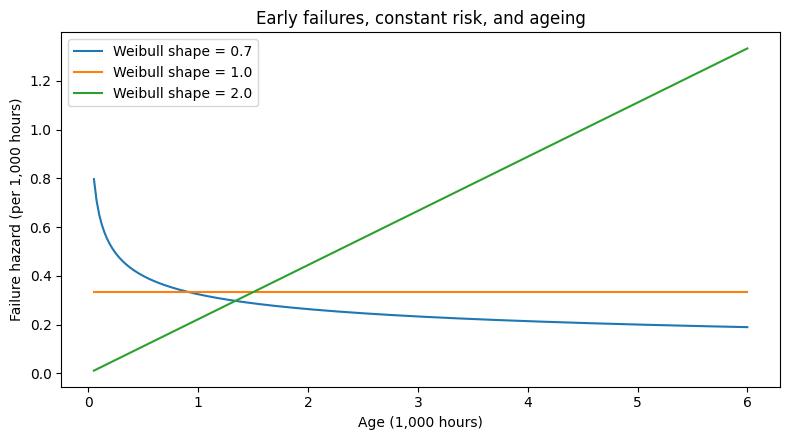

Erlang identity verified numerically.


In [3]:
# How Weibull shape affects the failure hazard.
t_display = np.linspace(0.05, 6, 250)
for shape in [0.7, 1.0, 2.0]:
    hazard = (shape / 3) * (t_display / 3) ** (shape - 1)
    plt.plot(t_display, hazard, label=f'Weibull shape = {shape}')
plt.xlabel('Age (1,000 hours)')
plt.ylabel('Failure hazard (per 1,000 hours)')
plt.title('Early failures, constant risk, and ageing')
plt.legend()
show_plot()

# Verify the report's Erlang survival identity against the Gamma implementation.
k, rate = 4, 1.5
manual_survival = np.exp(-rate * t_display) * sum(
    (rate * t_display)**j / factorial(j) for j in range(k))
assert np.allclose(manual_survival, stats.gamma.sf(t_display, a=k, scale=1/rate))
print('Erlang identity verified numerically.')

## 1. Simulated server lifetimes

For a two-parameter Weibull distribution with shape β and scale η,

\[R(t) = \exp[-(t/\eta)^\beta],\qquad h(t)=\frac{\beta}{\eta}(t/\eta)^{\beta-1}.\]

A shape parameter β > 1 implies an increasing instantaneous failure hazard. The scale η is **not** the mean lifetime: at `t = η`, `R(η) = exp(-1)` (approximately 36.8% surviving).


In [4]:
BETA_TRUE, ETA_TRUE = 2.0, 3.0
T = ETA_TRUE * rng_data.weibull(BETA_TRUE, N)
tgrid = np.linspace(0.02, 6.5, 220)

def weibull_R(t, beta, eta):
    return np.exp(-(np.asarray(t) / eta)**beta)

def weibull_h(t, beta, eta):
    return beta / eta * (np.asarray(t) / eta)**(beta - 1)

def empirical_R(sample, t):
    sample = np.sort(sample)
    return (len(sample) - np.searchsorted(sample, t, side='right')) / len(sample)

summary = pd.Series(T).describe()
summary


count    1000.000000
mean        2.795121
std         1.423023
min         0.111793
25%         1.738862
50%         2.621294
75%         3.655585
max         9.582643
dtype: float64

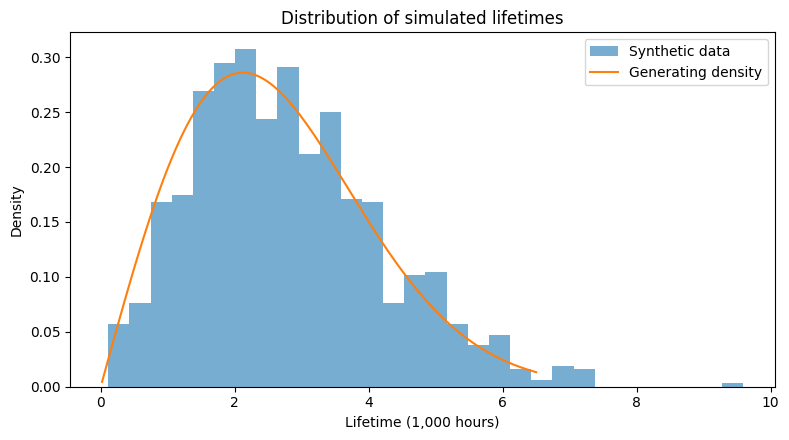

In [5]:
plt.hist(T, bins=30, density=True, alpha=0.6, label='Synthetic data')
plt.plot(tgrid, stats.weibull_min.pdf(tgrid, BETA_TRUE, scale=ETA_TRUE),
         label='Generating density')
plt.xlabel('Lifetime (1,000 hours)'); plt.ylabel('Density'); plt.legend()
plt.title('Distribution of simulated lifetimes')
show_plot()


## 2. Empirical survival and failure hazard

The empirical reliability function is the fraction of observed lifetimes at least as large as `t`:

\[\widehat R(t) = \frac{\#\{T_i\ge t\}}{n}.\]

For the time-binned hazard display, the estimator is

\[\widehat h_j = \frac{d_j}{Y_j\,\Delta t_j},\]

where `d_j` is the count of failures in bin `j` and `Y_j` is the number at risk at the beginning of that bin. It is a local approximation sensitive to the bin width. A zero failure count can produce a zero estimate even when the underlying hazard is positive; if `Y_j = 0` it is undefined. Tail observations are sparse, and noise should not be interpreted as a mathematical rounding error.


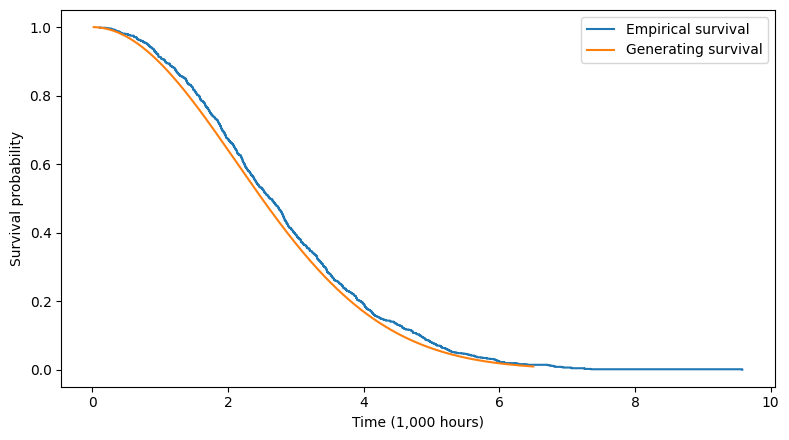

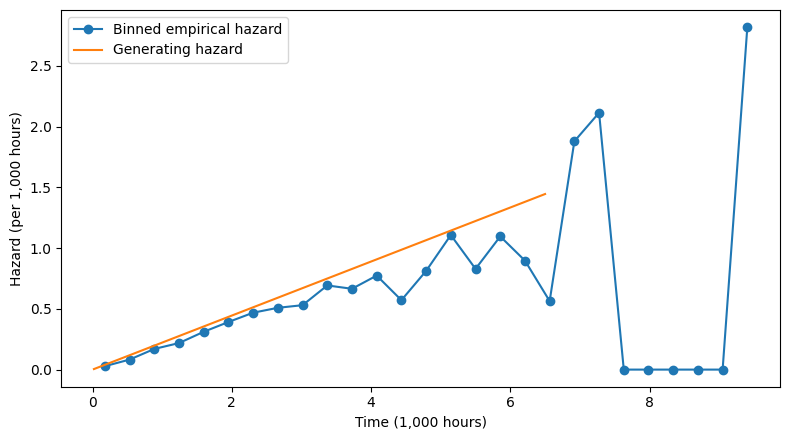

,start,end,failures,at_risk,hazard
0,0.000000,0.354913,10,1000,0.028176
1,0.354913,0.709825,29,990,0.082536
2,0.709825,1.064738,58,961,0.170053
3,1.064738,1.419651,70,903,0.218418
4,1.419651,1.774564,92,833,0.311187
5,1.774564,2.129476,103,741,0.391649
6,2.129476,2.484389,106,638,0.468127
7,2.484389,2.839302,96,532,0.508438
8,2.839302,3.194214,82,436,0.529915
9,3.194214,3.549127,87,354,0.692460


In [6]:
plt.step(np.sort(T), empirical_R(T, np.sort(T)), where='post', label='Empirical survival')
plt.plot(tgrid, weibull_R(tgrid, BETA_TRUE, ETA_TRUE), label='Generating survival')
plt.xlabel('Time (1,000 hours)'); plt.ylabel('Survival probability'); plt.legend()
show_plot()

edges = np.linspace(0, T.max() + 1e-8, 28)
counts, _ = np.histogram(T, bins=edges)
at_risk = N - np.searchsorted(np.sort(T), edges[:-1], side='left')
widths = np.diff(edges)
centers = (edges[:-1] + edges[1:]) / 2
haz_emp = np.divide(counts, at_risk * widths,
                    out=np.full(len(counts), np.nan), where=at_risk > 0)
plt.plot(centers, haz_emp, 'o-', label='Binned empirical hazard')
plt.plot(tgrid, weibull_h(tgrid, BETA_TRUE, ETA_TRUE), label='Generating hazard')
plt.xlabel('Time (1,000 hours)'); plt.ylabel('Hazard (per 1,000 hours)'); plt.legend()
show_plot()
pd.DataFrame({'start': edges[:-1], 'end': edges[1:], 'failures': counts,
              'at_risk': at_risk, 'hazard': haz_emp})


## 3. Estimation by Weibull probability plot and maximum likelihood

The Weibull linearization is

\[\log[-\log R(t)]=\beta\log t - \beta\log\eta.\]

We use median-rank plotting positions `F_i = (i - 0.3)/(n + 0.4)` so no logarithms of zero are needed. These positions are a plotting convention, not exact equalities to the empirical CDF.

We also estimate shape and scale by maximum likelihood, with location fixed at zero. The fitted MLE is used consistently in subsequent bootstrap computations and tests. The historical report used a different sample; the coefficients in this notebook must not be presented as identical to those archival results.


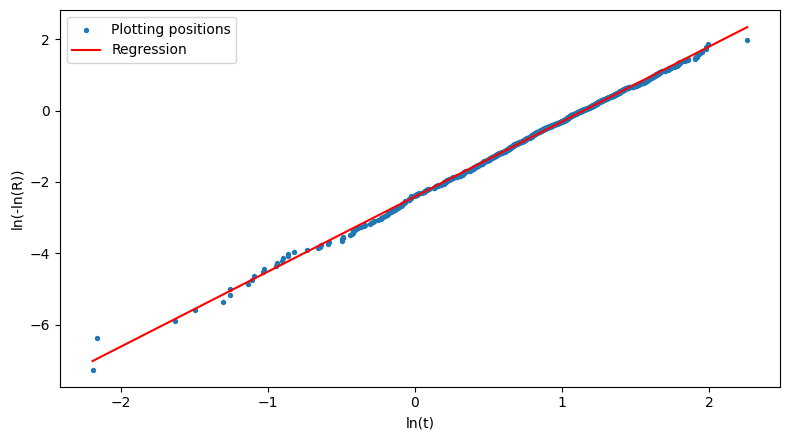

,Method,beta,eta
0,Generating model,2.000000,3.000000
1,Probability plot,2.103974,3.152088
2,MLE,2.066022,3.157301


In [7]:
sorted_T = np.sort(T)
ranks = np.arange(1, N + 1)
F_plot = (ranks - 0.3) / (N + 0.4)
X = np.log(sorted_T)
Y = np.log(-np.log1p(-F_plot))
reg = stats.linregress(X, Y)
beta_paper = reg.slope
eta_paper = np.exp(-reg.intercept / reg.slope)
beta_hat, _, eta_hat = stats.weibull_min.fit(T, floc=0)
plt.scatter(X, Y, s=8, label='Plotting positions')
plt.plot(X, reg.intercept + reg.slope * X, color='red', label='Regression')
plt.xlabel('ln(t)'); plt.ylabel('ln(-ln(R))'); plt.legend()
show_plot()
params = pd.DataFrame({'Method': ['Generating model', 'Probability plot', 'MLE'],
                       'beta': [BETA_TRUE, beta_paper, beta_hat],
                       'eta': [ETA_TRUE, eta_paper, eta_hat]})
params


## 4. Reliability of series and parallel systems

The example uses two independent, nonrepairable exponential components with rates 0.5 and 1 per thousand hours. In a **series** system the lifetime is `min(T1, T2)`. In an ideal active-redundancy **parallel** system the lifetime is `max(T1, T2)`.

The system comparison is a separate exponential demonstration, not a physical decomposition or fitted component model of the simulated Weibull fleet. Common-cause failures are omitted.


In [8]:
rate1, rate2 = 0.5, 1.0
T1 = rng_arch.exponential(1 / rate1, 10000)
T2 = rng_arch.exponential(1 / rate2, 10000)
mean_series = 1 / (rate1 + rate2)
mean_parallel = 1 / rate1 + 1 / rate2 - mean_series
architecture = pd.DataFrame({'Architecture': ['Series', 'Parallel'],
 'Simulated mean (1,000 h)': [np.minimum(T1, T2).mean(), np.maximum(T1, T2).mean()],
 'Theoretical mean (1,000 h)': [mean_series, mean_parallel]})
architecture['Relative error (%)'] = 100 * abs(architecture.iloc[:, 1] / architecture.iloc[:, 2] - 1)
architecture


,Architecture,"Simulated mean (1,000 h)","Theoretical mean (1,000 h)",Relative error (%)
0,Series,0.664561,0.666667,0.315921
1,Parallel,2.355506,2.333333,0.950244


## 5. Residual survival and preventive maintenance decision rule

For an item still operational at age `t0`,

\[P(T>t_0+x\mid T>t_0)=\frac{R(t_0+x)}{R(t_0)},\qquad
m(t_0)=\frac{1}{R(t_0)}\int_{t_0}^{\infty}R(u)\,du.\]

Both generating-model and fitted-model values are reported to keep theoretical and estimated quantities separate.

### Illustrative 10% conditional failure-risk rule

Following the original case study, assume a preventive intervention costs `C` while an unexpected failure incurs `10C`. The simplified equation `10C × P(failure during the horizon | alive at t0) = C` defines a **10% conditional failure-risk threshold**.

**It is not a proven optimal replacement policy:** this static comparison does not account for the time value of deferred intervention, full operational costs, inspection schedules or long-run renewal rates. The resulting time is only a risk-based planning threshold under the stated assumptions.


In [9]:
t0, extra = 1.5, 0.5

def residual_stats(beta, eta):
    log_survival_ratio = -((t0 + extra) / eta)**beta + (t0 / eta)**beta
    mrl = integrate.quad(lambda u: np.exp(-(u / eta)**beta + (t0 / eta)**beta),
                         t0, np.inf)[0]
    return np.exp(log_survival_ratio), mrl

maintenance = pd.DataFrame([residual_stats(BETA_TRUE, ETA_TRUE),
                            residual_stats(beta_hat, eta_hat)],
                           index=['Generating model', 'MLE'],
                           columns=['Survival for 500 more hours', 'Mean residual life (1,000 h)'])
risk_threshold = 0.1
x_star = eta_hat * ((t0 / eta_hat)**beta_hat - np.log1p(-risk_threshold))**(1 / beta_hat) - t0
print(f'Additional time to risk threshold : {1000*x_star:.1f} additional hours')
print(f'Corresponding age : {1000*(t0+x_star):.1f} h (not a proven cost optimum)')
maintenance


Additional time to risk threshold : 319.5 additional hours
Corresponding age : 1819.5 h (not a proven cost optimum)


,Survival for 500 more hours,"Mean residual life (1,000 h)"
Generating model,0.823292,1.636924
MLE,0.839911,1.730034


## 6. Comparison of lifetime distributions

We fit three candidate lifetime models to the same sample: (i) Weibull (two parameters), (ii) exponential (one rate), and (iii) an Erlang distribution (integer shape `k` selected by likelihood search, with a fitted rate). The Erlang is a gamma distribution restricted to positive integer shape.

We compare fitted densities, survival curves, the mean squared survival discrepancy on a display grid, and the exact empirical-CDF Kolmogorov–Smirnov statistic. These metrics are descriptive until the bootstrap test is performed in Section 8.


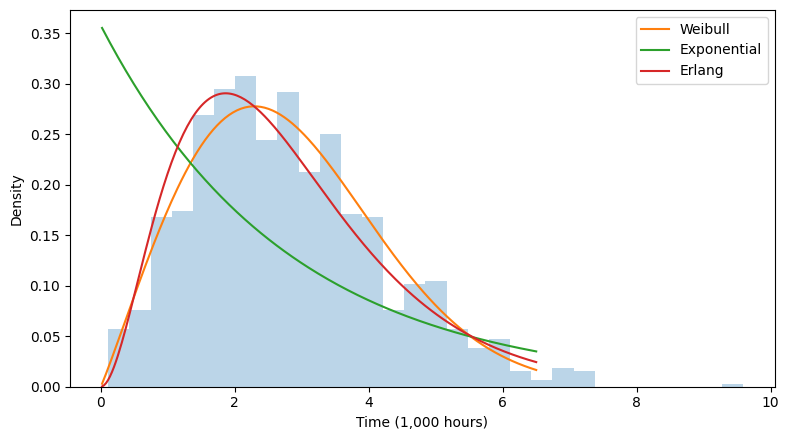

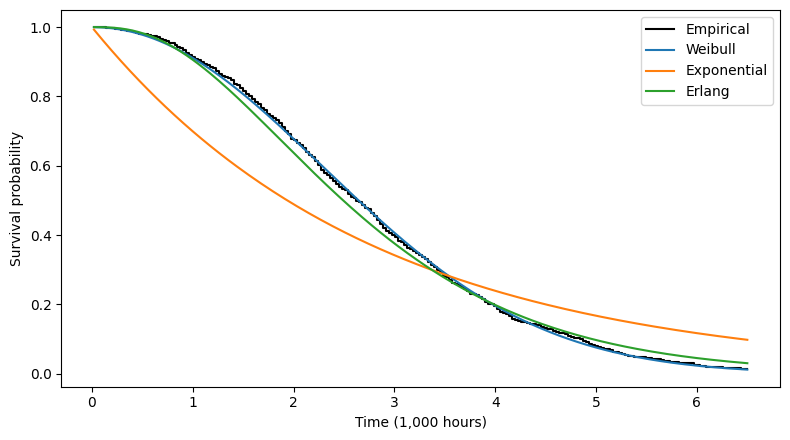

,Model,Parameters,MSE on survival,KS distance
0,Weibull,"(2.0660218639065038, 3.1573006363954406)",0.000046,0.017209
1,Exponential,"(0.35776623641083344,)",0.016175,0.238733
2,Erlang,"(3, 1.0732987092325004)",0.000459,0.046409


In [10]:
def fit_model(sample, model):
    if model == 'Weibull':
        b, _, e = stats.weibull_min.fit(sample, floc=0)
        return stats.weibull_min(b, scale=e), (b, e)
    if model == 'Exponential':
        mean = np.mean(sample)
        return stats.expon(scale=mean), (1 / mean,)
    candidates = []
    for k in range(1, 16):
        rate = k / np.mean(sample)
        dist = stats.gamma(k, scale=1 / rate)
        candidates.append((np.sum(dist.logpdf(sample)), k, rate))
    _, k, rate = max(candidates)
    return stats.gamma(k, scale=1 / rate), (k, rate)

def ks_distance(sample, dist):
    values = dist.cdf(np.sort(sample))
    n = len(sample)
    return max(np.max(np.arange(1, n + 1) / n - values),
               np.max(values - np.arange(n) / n))

models = ['Weibull', 'Exponential', 'Erlang']
fits = {model: fit_model(T, model) for model in models}
comparison = pd.DataFrame([{'Model': model, 'Parameters': fits[model][1],
 'MSE on survival': np.mean((empirical_R(T, tgrid) - fits[model][0].sf(tgrid))**2),
 'KS distance': ks_distance(T, fits[model][0])} for model in models])
plt.hist(T, bins=30, density=True, alpha=0.3)
for model in models:
    plt.plot(tgrid, fits[model][0].pdf(tgrid), label=model)
plt.xlabel('Time (1,000 hours)'); plt.ylabel('Density'); plt.legend()
show_plot()
plt.step(tgrid, empirical_R(T, tgrid), where='post', label='Empirical', color='black')
for model in models:
    plt.plot(tgrid, fits[model][0].sf(tgrid), label=model)
plt.xlabel('Time (1,000 hours)'); plt.ylabel('Survival probability'); plt.legend()
show_plot()
comparison


## 7. Nonparametric bootstrap for Weibull uncertainty

We resample the observed synthetic lifetimes with replacement and refit the Weibull MLE for each bootstrap sample. Percentile intervals and coefficient of variation quantify estimation variability **conditional on the Weibull model and on the simulated sample**. A bootstrap interval excluding β = 1 is consistent with increasing fitted hazard but does not establish aging in real server hardware.


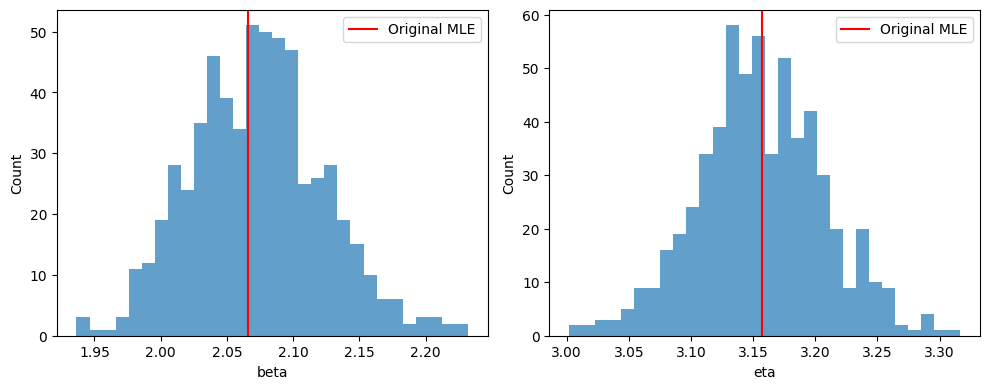

Bootstrap fraction with beta > 1 : 1.0


,Parameter,MLE estimate,Bootstrap mean,Bootstrap SD,CV (%),CI 95% lower,CI 95% upper
0,beta,2.066022,2.072902,0.049901,2.407301,1.983032,2.177052
1,eta,3.157301,3.156102,0.051107,1.619305,3.056580,3.255676


In [11]:
boot = np.empty((B_BOOT, 2))
for b in range(B_BOOT):
    sample = rng_boot.choice(T, size=N, replace=True)
    bh, _, eh = stats.weibull_min.fit(sample, floc=0)
    boot[b] = bh, eh
boot_sd = boot.std(axis=0, ddof=1)
boot_ci = np.quantile(boot, [0.025, 0.975], axis=0)
bootstrap_params = pd.DataFrame({'Parameter': ['beta', 'eta'],
 'MLE estimate': [beta_hat, eta_hat], 'Bootstrap mean': boot.mean(axis=0),
 'Bootstrap SD': boot_sd, 'CV (%)': 100*boot_sd/boot.mean(axis=0),
 'CI 95% lower': boot_ci[0], 'CI 95% upper': boot_ci[1]})
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for j, label in enumerate(['beta', 'eta']):
    axes[j].hist(boot[:, j], bins=30, alpha=0.7)
    axes[j].axvline([beta_hat, eta_hat][j], color='red', label='Original MLE')
    axes[j].set_xlabel(label); axes[j].set_ylabel('Count'); axes[j].legend()
show_plot()
print('Bootstrap fraction with beta > 1 :', np.mean(boot[:, 0] > 1))
bootstrap_params


### Pointwise uncertainty for the survival and hazard curves

The plotted reference is the **fitted model's** hazard/survival curve, not the binned empirical hazard and not the generating curve. Curves are reevaluated using each bootstrap parameter pair.

Shaded percentile intervals are **pointwise** 95% intervals, not simultaneous 95% confidence bands over an entire curve. Their width depends on the model assumptions; smooth fitted curves do not eliminate uncertainty in the sparsely populated tail.


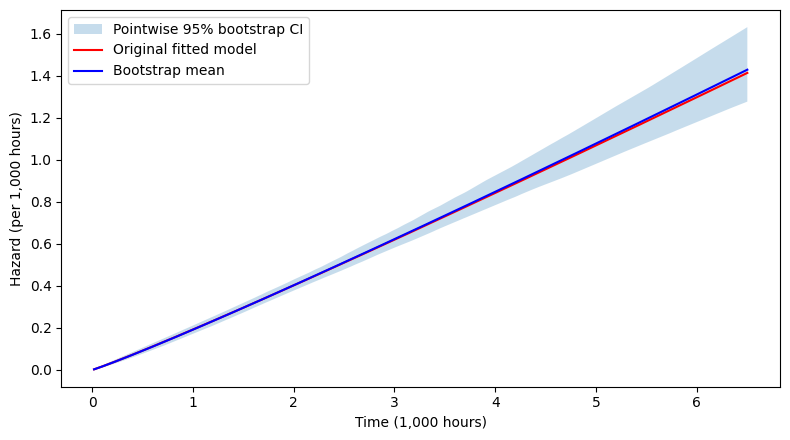

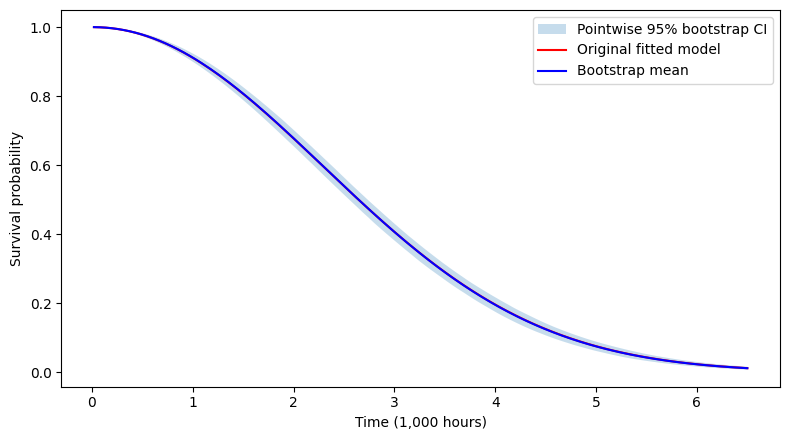

95% bootstrap CI for age at risk threshold (h) : [1799.35644131 1840.69919694]


In [12]:
h_boot = weibull_h(tgrid[None, :], boot[:, 0, None], boot[:, 1, None])
R_boot = weibull_R(tgrid[None, :], boot[:, 0, None], boot[:, 1, None])
for curves, estimate, ylabel, name in [
    (h_boot, weibull_h(tgrid, beta_hat, eta_hat), 'Hazard (per 1,000 hours)', 'hazard_bootstrap'),
    (R_boot, weibull_R(tgrid, beta_hat, eta_hat), 'Survival probability', 'survival_bootstrap')]:
    lower, upper = np.quantile(curves, [0.025, 0.975], axis=0)
    plt.fill_between(tgrid, lower, upper, alpha=0.25, label='Pointwise 95% bootstrap CI')
    plt.plot(tgrid, estimate, color='red', label='Original fitted model')
    plt.plot(tgrid, curves.mean(axis=0), color='blue', label='Bootstrap mean')
    plt.xlabel('Time (1,000 hours)'); plt.ylabel(ylabel); plt.legend()
    show_plot()

age_boot = boot[:, 1] * ((t0 / boot[:, 1])**boot[:, 0] - np.log1p(-risk_threshold))**(1 / boot[:, 0])
print('95% bootstrap CI for age at risk threshold (h) :',
      1000*np.quantile(age_boot, [0.025, 0.975]))


## 8. Formal statistical tests

### 8.1 Likelihood-ratio test for the exponential special case

Under `H0: β = 1`, the Weibull family reduces to the exponential distribution. Test against `H1: β ≠ 1` using

\[LRT=2(\ell_{\mathrm{Weibull}}-\ell_{\mathrm{Exp}})\overset{H_0}{\longrightarrow}\chi_1^2.\]

This asymptotic result follows from Wilks' theorem under standard regularity conditions. The one degree of freedom corresponds to the difference in the number of free parameters. The LRT is two-sided; an estimated β > 1 determines the direction of the inferred fitted hazard behavior.


In [13]:
ll_weibull = np.sum(fits['Weibull'][0].logpdf(T))
ll_exp = np.sum(fits['Exponential'][0].logpdf(T))
lrt = 2 * (ll_weibull - ll_exp)
assert lrt >= -1e-6
p_lrt = stats.chi2.sf(max(lrt, 0), df=1)
lrt_results = pd.Series({'LRT': lrt, 'df': 1,
                         '5% critical value': stats.chi2.ppf(0.95, 1), 'p-value': p_lrt})
lrt_results


LRT                   6.204685e+02
df                    1.000000e+00
5% critical value     3.841459e+00
p-value              5.913739e-137
dtype: float64

### 8.2 Parametric-bootstrap Kolmogorov–Smirnov goodness-of-fit test

Since model parameters are estimated using the data under test, a naive simple-null KS p-value is not appropriate. Instead, simulate samples from each fitted candidate; for every simulated sample, **refit the model (including choosing the Erlang integer shape)** and recompute the KS distance.

The Monte Carlo p-value uses the plus-one correction `(1 + # simulated distances ≥ observed distance)/(B + 1)`. Its resolution is `1/(B + 1)`. The Erlang shape search is repeated in each simulation; this is still an approximation for discrete model selection.


In [14]:
ks_rows = []
for model in models:
    dist, _ = fits[model]
    observed = ks_distance(T, dist)
    simulated = np.empty(B_KS)
    for b in range(B_KS):
        sample = dist.rvs(size=N, random_state=rng_ks)
        fitted_b, _ = fit_model(sample, model)
        simulated[b] = ks_distance(sample, fitted_b)
    pvalue = (1 + np.count_nonzero(simulated >= observed)) / (B_KS + 1)
    ks_rows.append({'Model': model, 'KS': observed, 'bootstrap p-value': pvalue,
                    'Reject at 5%': pvalue < 0.05})
ks_results = pd.DataFrame(ks_rows)
ks_results


,Model,KS,bootstrap p-value,Reject at 5%
0,Weibull,0.017209,0.660000,False
1,Exponential,0.238733,0.003333,True
2,Erlang,0.046409,0.003333,True


### 8.3 Pearson grouped goodness-of-fit with bootstrap calibration

We create 12 equiprobable bins under the fitted Weibull, spanning `[0, +∞)`; each has expected count `n / 12`. Both observed and expected totals are asserted to equal `n`.

\[Q=\sum_{j=1}^{12}\frac{(O_j-E_j)^2}{E_j}.\]

A conventional `χ²(K−1−p)` reference requires appropriate estimation/binning assumptions. Here we instead calibrate the grouped statistic by parametric bootstrap, repeating model estimation **and** bin construction in every replication. In particular, this avoids the inconsistent historical table whose observed and expected counts did not sum to 1,000.

A non-rejection is not a probability that the Weibull model is true.


In [15]:
K = 12

def pearson_fitted(sample):
    fitted, _ = fit_model(sample, 'Weibull')
    bounds = fitted.ppf(np.linspace(0, 1, K + 1))
    bounds[0], bounds[-1] = 0, np.inf
    observed, _ = np.histogram(sample, bins=bounds)
    expected = np.full(K, len(sample)/K)
    assert observed.sum() == len(sample)
    assert np.isclose(expected.sum(), len(sample))
    q = np.sum((observed - expected)**2 / expected)
    return q, bounds, observed, expected

q_obs, bounds, obs, exp = pearson_fitted(T)
q_sim = np.empty(B_KS)
for b in range(B_KS):
    sample = fits['Weibull'][0].rvs(size=N, random_state=rng_ks)
    q_sim[b] = pearson_fitted(sample)[0]
p_pearson = (1 + np.count_nonzero(q_sim >= q_obs)) / (B_KS + 1)
pearson_table = pd.DataFrame({'Lower bound': bounds[:-1], 'Upper bound': bounds[1:],
 'Observed': obs, 'Expected': exp, 'Contribution': (obs-exp)**2/exp})
print(f'Pearson Q = {q_obs:.4f} ; bootstrap p-value = {p_pearson:.4f}')
pearson_table


Pearson Q = 12.6800 ; bootstrap p-value = 0.2233


,Lower bound,Upper bound,Observed,Expected,Contribution
0,0.000000,0.968384,81,83.333333,0.065333
1,0.968384,1.385305,75,83.333333,0.833333
2,1.385305,1.727499,89,83.333333,0.385333
3,1.727499,2.039655,93,83.333333,1.121333
4,2.039655,2.340980,93,83.333333,1.121333
5,2.340980,2.644064,72,83.333333,1.541333
6,2.644064,2.960460,94,83.333333,1.365333
7,2.960460,3.304346,72,83.333333,1.541333
8,3.304346,3.698087,90,83.333333,0.533333
9,3.698087,4.187057,85,83.333333,0.033333


## 9. Numerical consistency checks

The final cell checks key mathematical properties and makes sure that the bootstrap and test calculations are finite. It does not export any files.

In [16]:
assert np.all(T > 0)
assert np.all(np.diff(empirical_R(T, tgrid)) <= 0)
assert np.isclose(weibull_R(ETA_TRUE, BETA_TRUE, ETA_TRUE), np.exp(-1))
assert mean_parallel > mean_series
assert np.isclose(architecture['Theoretical mean (1,000 h)'].iloc[0], 2/3)
assert np.isclose(architecture['Theoretical mean (1,000 h)'].iloc[1], 7/3)
assert abs((1 - weibull_R(t0 + x_star, beta_hat, eta_hat) /
            weibull_R(t0, beta_hat, eta_hat)) - risk_threshold) < 1e-10
assert np.all(np.isfinite(boot))
assert np.isclose(pearson_table['Observed'].sum(), N)
assert np.isclose(pearson_table['Expected'].sum(), N)
print('All numerical consistency checks passed.')

All numerical consistency checks passed.


## Conclusion and scientific limitations

The new simulation illustrates the central methods of the original French report: descriptive reliability analysis, Weibull probability plotting and maximum likelihood, theoretical and simulated series/parallel architectures, remaining useful life, a preventive-maintenance risk threshold, alternative lifetime distributions, bootstrap uncertainty, and formal goodness-of-fit tests.

**Interpretation matters:**

- Because the data were *generated from Weibull*, their agreement with Weibull is not evidence that real servers obey this distribution.
- The exponential-model likelihood-ratio test examines constant versus nonconstant Weibull hazard; the fitted $\beta>1$ indicates an increasing hazard *in this simulated setting*.
- A goodness-of-fit test that does not reject a model does **not** prove it is true.
- The maintenance age corresponding to a 10% conditional failure probability is an **illustrative risk threshold**, not an economically optimal replacement age. A complete cost/renewal model would be needed for optimization.
- The bootstrap intervals for survival and hazard are **pointwise**, not simultaneous confidence bands. The analysis assumes uncensored, independent lifetimes and fixed Weibull location at zero; real industrial data frequently require censoring, covariates, and competing-risk modeling.

**Reproducibility:** This notebook computes all numerical results from its own synthetic sample. They need not match figures in the original French PDF; any discrepancy must not be masked by inserting historical numbers.